[Status] 1. Loading Data & Computing TPI / Fractal Ripples (V31)...
[Status] 2. Slicing with 5 Independent Layer Buffers (V31)...
[Status] 3. Slicing 48 Panels with Local Bed-Tilt Dynamic Z (V31)...
[Status] 4. Writing 5-Pass Bidirectional Optimized G-Code Files...
[Status] 5. Rendering Gamji Geumni V31 Visual Map...


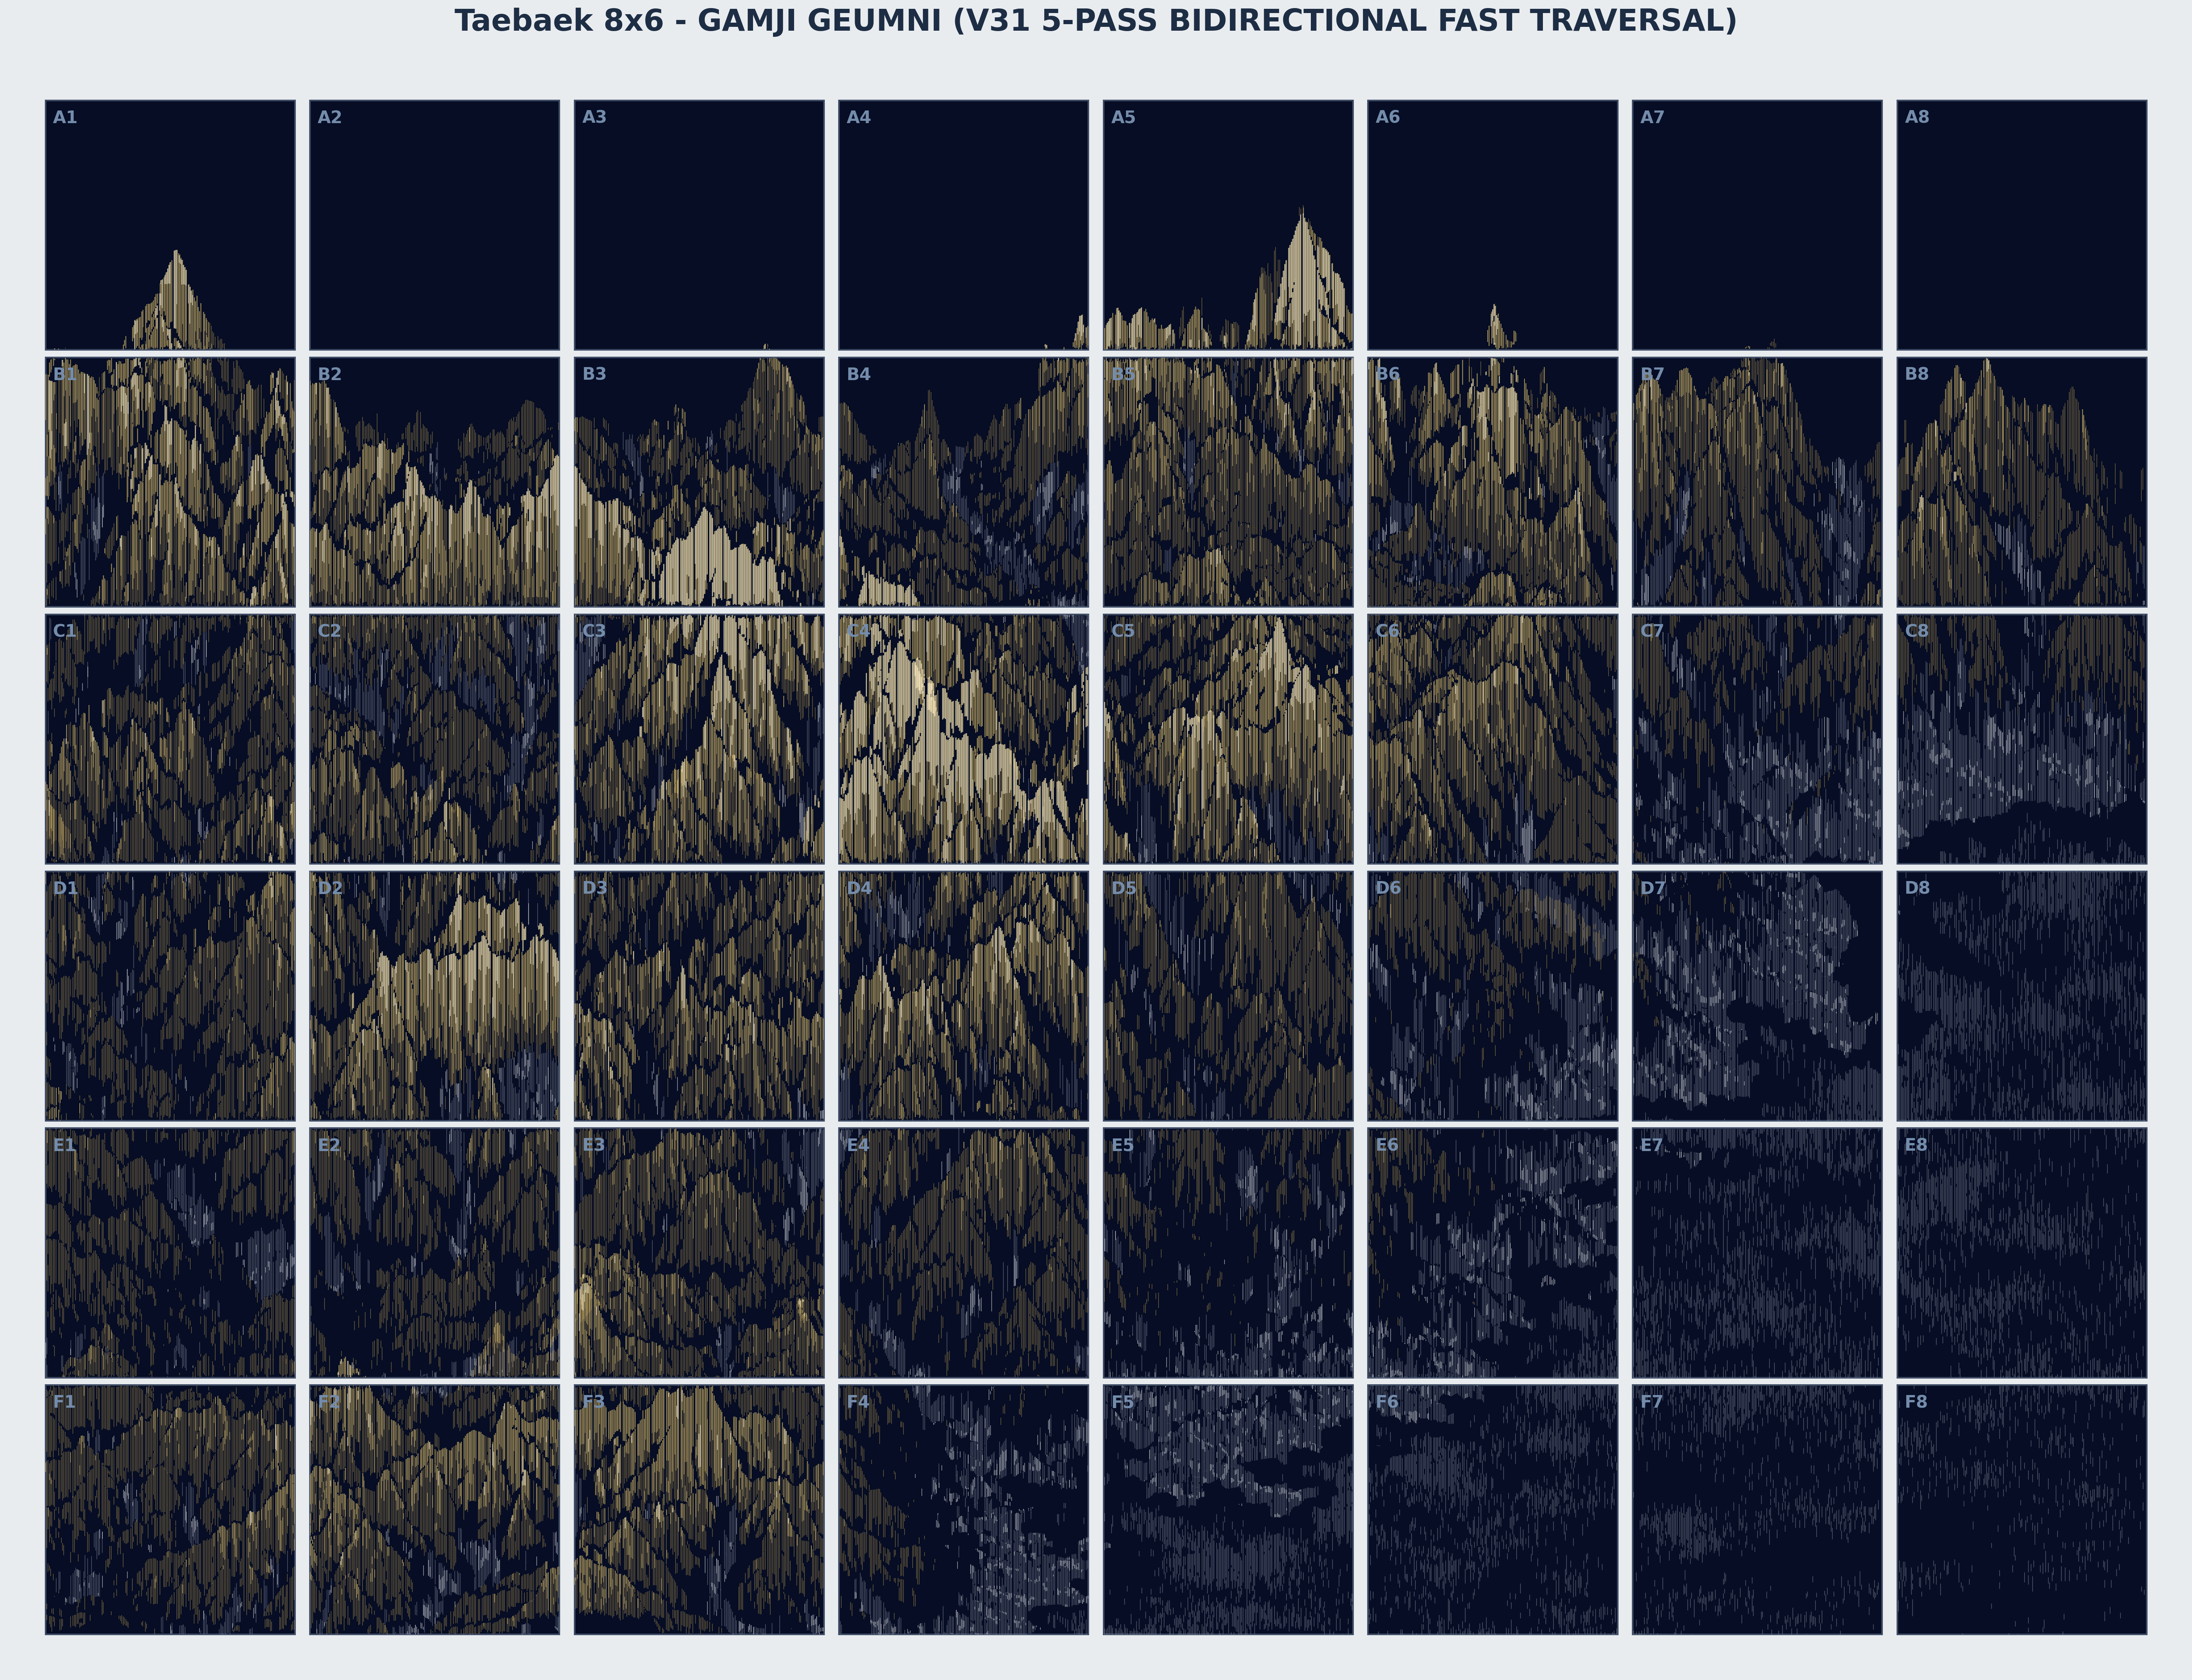

[Success] Gamji Geumni V31 G-Codes & Map created! Runtime: 83.00s


In [12]:
import math
import os
import random
import time
import cv2
from matplotlib.collections import LineCollection
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from scipy.interpolate import CubicSpline, interp1d

start_time = time.time()

# ==============================================================================
# [A-1] 🌟 [수치조정] USER TUNING PARAMETERS (V31 Optimized Bidirectional Passes)
# ==============================================================================
# 1. 패널 1장 베드(Local Y: 0~330mm) 기준 기울기 보정 파라미터 (±1.0mm)
Z_BASE_DRAW             = -5.3   # [기준깊이] 패널 정중앙(Y=165mm, 접점 -5.0 기준) 0.3mm 필압 깊이
Z_TILT_PANEL_BOTTOM     = +1.0   # [수치조정] 패널 하단(Y=0mm)에서 들어올릴 높이 (+1.0mm -> Z=-4.3)
Z_TILT_PANEL_TOP        = -1.0   # [수치조정] 패널 상단(Y=330mm)에서 더 누를 깊이 (-1.0mm -> Z=-6.3)

# 2. 중턱 운무/여백 그라데이션 (금 -> 여백 -> 은)
ELEVATION_SILVER_CUTOFF = 0.22   
TPI_GOLD_FADE_START     = -0.005 
TPI_SILVER_MIST_START   = -0.020 
COAST_BLANK_DIST_MM     = 10.0   

# 3. 운무 2단계(Silver P2) 고주파 프랙탈 패턴 제어 
MIST_NOISE_P2_THRESH    = 0.58   

# 4. 금묵 5단계(5-Tier) 톤 임계값
TONE_GOLD_LV1_THRESH    = 1.70   
TONE_GOLD_LV2_THRESH    = 2.30   
TONE_GOLD_LV3_THRESH    = 3.00   
TONE_GOLD_LV4_THRESH    = 3.70   
TONE_GOLD_LV5_THRESH    = 4.30   

# 5. Normal Map 물리적 결 변위(Displacement wobbling)
NORMAL_NZ_THRESH        = 0.85   
TEXTURE_WOBBLE_STRENGTH = 0.35   
TEXTURE_INFLUENCE_PROB  = 0.45   
NORMAL_BOOST_VALUE      = 1.50   
NORMAL_CUT_VALUE        = 1.50   

# 6. 바다 유기적 파도 
SEA_BASE_DENSITY        = 0.50   
SEA_SWELL_CONTRAST      = 0.60
SEA_FADE_DISTANCE       = 950.0

# ==============================================================================
# [A-2] Canvas Configuration (8x6)
# ==============================================================================
PANEL_W, PANEL_H = 330.0, 330.0 
MIN_DRAW, MAX_DRAW = 0.0, 330.0 
GAP_X, GAP_Y = 20.0, 10.0  
COLS, ROWS = 8, 6  
TOTAL_W = PANEL_W * COLS + GAP_X * (COLS - 1)
TOTAL_H = PANEL_H * ROWS + GAP_Y * (ROWS - 1)

output_dir = "Taebaek_GamjiGeumni_V31"
if not os.path.exists(output_dir): os.makedirs(output_dir)
gcode_dir = os.path.join(output_dir, "GCODES")
if not os.path.exists(gcode_dir): os.makedirs(gcode_dir)

panels = []
row_names = ['F', 'E', 'D', 'C', 'B', 'A']
for r_idx in range(ROWS):
    for c_idx in range(COLS):
        panels.append((f"{row_names[r_idx]}{c_idx+1}", c_idx * (PANEL_W + GAP_X), r_idx * (PANEL_H + GAP_Y)))

# ==============================================================================
# [B] Hardware & Bidirectional G-Code Helpers
# ==============================================================================
FEED_RATE_DRAW = 5000       
FEED_RATE_TRAVEL = 10000    
FEED_RATE_WIPE = 5000       
FEED_RATE_Z_FAST = 4000     

Z_HOVER, Z_SAFE = 0.0, 0.0  

def get_panel_tilt_z(local_y):
    tilt_offset = np.interp(local_y, [0.0, PANEL_H], [Z_TILT_PANEL_BOTTOM, Z_TILT_PANEL_TOP])
    return Z_BASE_DRAW + tilt_offset

ORDERED_LAYERS = [
    'silver_ink_p1', 
    'silver_ink_p2', 
    'gold_ink_p1', 
    'gold_ink_p2', 
    'gold_ink_p3'
]

STATIONS = {
    'silver_ink': {'x': -25.0, 'y': 50.0,  'limit': 600.0, 'dip_z': -12.0, 'name': 'Silver Ink'},
    'gold_ink':   {'x': -25.0, 'y': 140.0, 'limit': 600.0, 'dip_z': -12.0, 'name': 'Gold Ink'},
    'water':      {'x': -25.0, 'y': 260.0, 'limit': 0.0,   'dip_z': -11.0, 'name': 'Water Station'}
}

def get_stirring_dip_gcode(ink_name):
    sx, sy, sz = STATIONS[ink_name]['x'], STATIONS[ink_name]['y'], STATIONS[ink_name]['dip_z']
    sname = STATIONS[ink_name]['name']
    return [
        f"; --- STIRRING DIP: {sname} ---",
        f"G0 Z{Z_SAFE:.3f}",
        f"G0 X{sx:.3f} Y{sy:.3f} F{FEED_RATE_TRAVEL}",
        f"G1 Z{sz:.3f} F3000",
        "G4 P0.5",
        f"G2 X{sx+3.0:.3f} Y{sy:.3f} I1.5 J0.0 F1500",
        f"G2 X{sx-3.0:.3f} Y{sy:.3f} I-3.0 J0.0 F1500",
        f"G2 X{sx:.3f} Y{sy:.3f} I1.5 J0.0 F1500",
        f"G1 Y{sy+5.0:.3f} F2000", f"G1 Y{sy-5.0:.3f} F2000", f"G1 Y{sy:.3f} F2000",
        "G4 P0.5",
        f"G1 Z{sz+4.0:.3f} F{FEED_RATE_Z_FAST}",
        f"G1 X{sx+4.0:.3f} F{FEED_RATE_WIPE}", f"G1 X{sx-4.0:.3f} F{FEED_RATE_WIPE}", f"G1 X{sx:.3f} F{FEED_RATE_WIPE}",
        f"G0 Z{Z_HOVER:.3f}"
    ]

def get_deep_wash_20s_gcode():
    wx, wy, wz = STATIONS['water']['x'], STATIONS['water']['y'], STATIONS['water']['dip_z']
    gcode = [
        "; --- 20s DEEP WATER WASH ---",
        f"G0 Z{Z_SAFE:.3f}",
        f"G0 X{wx:.3f} Y{wy:.3f} F{FEED_RATE_TRAVEL}",
        f"G1 Z{wz:.3f} F3000",
        "G4 P2.0"
    ]
    for _ in range(4):
        gcode.extend([
            f"G1 Y{wy+12.0:.3f} F{FEED_RATE_WIPE}",
            f"G1 Y{wy-12.0:.3f} F{FEED_RATE_WIPE}",
            f"G1 X{wx+4.0:.3f} F{FEED_RATE_WIPE}",
            f"G1 X{wx-4.0:.3f} F{FEED_RATE_WIPE}",
            "G4 P1.5"
        ])
    gcode.extend([
        f"G1 X{wx:.3f} Y{wy:.3f} F{FEED_RATE_WIPE}",
        "G4 P2.0",
        f"G0 Z{Z_HOVER:.3f}"
    ])
    return gcode

# 🌟 양방향(위<->아래) 스네이크 최단거리 최적화 함수
def optimize_vertical_paths_bidirectional(paths, start_pos):
    if not paths or len(paths) <= 1: return paths
    remaining = [list(p) for p in paths]
    optimized = []
    curr_pos = start_pos
    
    while remaining:
        best_idx, best_dist, flip = 0, float('inf'), False
        for i, p in enumerate(remaining):
            d_start = math.hypot(p[0][0] - curr_pos[0], p[0][1] - curr_pos[1])
            d_end = math.hypot(p[-1][0] - curr_pos[0], p[-1][1] - curr_pos[1])
            if d_start < best_dist:
                best_dist, best_idx, flip = d_start, i, False
            if d_end < best_dist:
                best_dist, best_idx, flip = d_end, i, True
                
        next_p = remaining.pop(best_idx)
        if flip:
            next_p.reverse() # 최단 거리를 위해 선 긋기 방향을 뒤집어 스네이크 주행
        optimized.append(next_p)
        curr_pos = (next_p[-1][0], next_p[-1][1])
        
    return optimized

def generate_layer_gcode(paths, ink_name):
    if not paths: return []
    # 🌟 양방향 최단 경로 정렬기 적용
    opt_paths = optimize_vertical_paths_bidirectional(paths, (STATIONS[ink_name]['x'], STATIONS[ink_name]['y']))
    gcode = get_stirring_dip_gcode(ink_name)
    drawn_len = 0.0
    limit = STATIONS[ink_name]['limit']
    for pts in opt_paths:
        if len(pts) < 2: continue
        sx, sy, sz = np.clip(pts[0][0], MIN_DRAW, MAX_DRAW), np.clip(pts[0][1], MIN_DRAW, MAX_DRAW), pts[0][2]
        gcode.extend([f"G0 Z{Z_HOVER:.3f}", f"G0 X{sx:.3f} Y{sy:.3f} F{FEED_RATE_TRAVEL}", f"G1 Z{sz:.3f} F{FEED_RATE_Z_FAST}"]) 
        for i in range(1, len(pts)):
            px, py, pz = np.clip(pts[i][0], MIN_DRAW, MAX_DRAW), np.clip(pts[i][1], MIN_DRAW, MAX_DRAW), pts[i][2]
            gcode.append(f"G1 X{px:.3f} Y{py:.3f} Z{pz:.3f} F{FEED_RATE_DRAW}")
            drawn_len += math.hypot(px - sx, py - sy)
            sx, sy = px, py
        if drawn_len > limit:
            gcode.extend([f"G0 Z{Z_HOVER:.3f}"] + get_stirring_dip_gcode(ink_name))
            drawn_len = 0.0
    return gcode

def smooth_spline_3d(path, res_factor=2):
    if len(path) < 4: return path
    pts = np.array(path)
    dists = np.sqrt(np.sum(np.diff(pts[:, :2], axis=0)**2, axis=1))
    valid_idx = np.where(dists > 0.1)[0]
    pts = pts[np.append(valid_idx, len(pts)-1)]
    if len(pts) < 4: return path
    t = np.linspace(0, 1, len(pts))
    t_new = np.linspace(0, 1, len(pts) * res_factor)
    try:
        cs_x, cs_y, cs_z = CubicSpline(t, pts[:, 0]), CubicSpline(t, pts[:, 1]), CubicSpline(t, pts[:, 2])
        return np.vstack([cs_x(t_new), cs_y(t_new), cs_z(t_new)]).T.tolist()
    except: return path

def extract_splines(path, z_limit):
    segments, seg = [], []
    for pt in path:
        if pt[2] <= z_limit: seg.append(pt)
        else:
            if len(seg) > 2: segments.append(smooth_spline_3d(seg))
            seg = []
    if len(seg) > 2: segments.append(smooth_spline_3d(seg))
    return segments

def flush_seg(seg_list, layer_target, min_len=6):
    if len(seg_list) >= min_len:
        layer_target.extend(extract_splines(seg_list, -2.5))
    return []

def clip_segment_to_box(segment, min_x, max_x, min_y, max_y):
    clipped, curr = [], []
    for px, py, pz in segment:
        if min_x <= px <= max_x and min_y <= py <= max_y:
            curr.append((px, py, pz))
        else:
            if len(curr) > 1: clipped.append(curr)
            curr = []
    if len(curr) > 1: clipped.append(curr)
    return clipped

# ==============================================================================
# [C] Loading Analytics, TPI & High-Freq Ripple Noise
# ==============================================================================
print("[Status] 1. Loading Data & Computing TPI / Fractal Ripples (V31)...")
data_dir = r"F:\GIT\Datascape\TAEBAEK"
RES_W, RES_H = 2000, 1500 

def load_tiff(filename):
    try:
        with rasterio.open(os.path.join(data_dir, filename)) as src:
            arr = np.where(src.read(1) < 0, 0, src.read(1))
            return cv2.resize(arr, (RES_W, RES_H), interpolation=cv2.INTER_LINEAR)
    except: return np.zeros((RES_H, RES_W))

raw_dem = load_tiff('Taebaek_DEM.tif')
dem_norm = np.clip(raw_dem / (np.max(raw_dem) + 1e-5), 0, 1)

dem_blur_macro = cv2.GaussianBlur(dem_norm, (181, 181), 0) 
tpi_map = dem_norm - dem_blur_macro 

norm_map = cv2.imread(os.path.join(data_dir, 'Taebaek_Normal.png'), cv2.IMREAD_UNCHANGED)
has_normal = False
if norm_map is not None:
    norm_map = cv2.resize(norm_map, (RES_W, RES_H), interpolation=cv2.INTER_LINEAR)
    Nz = (norm_map[:, :, 0].astype(float) - 128.0) / 127.5
    Nx = (norm_map[:, :, 2].astype(float) - 128.0) / 127.5
    has_normal = True

H, W = dem_norm.shape
dy, dx = np.gradient(dem_norm)
slope = np.clip(np.sqrt(dx**2 + dy**2) * 5.0, 0, 1)

dem_blur_fine = cv2.GaussianBlur(dem_norm, (5, 5), 0)
lap_fine = cv2.Laplacian(dem_blur_fine, cv2.CV_64F)
ridge_crest = np.clip(-lap_fine * 20.0, 0.0, 1.0)
valley_slit_val = np.clip(lap_fine * 32.0, 0.0, 1.0)

sea_noise_coarse = cv2.resize(np.random.rand(35, 45), (W, H), interpolation=cv2.INTER_CUBIC)
sea_noise_fine = cv2.resize(np.random.rand(90, 120), (W, H), interpolation=cv2.INTER_CUBIC)
sea_organic_map = (sea_noise_coarse * 0.65) + (sea_noise_fine * 0.35)

mist_n1 = cv2.resize(np.random.rand(500, 650), (W, H), interpolation=cv2.INTER_CUBIC)
mist_n2 = cv2.resize(np.random.rand(1000, 1300), (W, H), interpolation=cv2.INTER_CUBIC)
mist_base = (mist_n1 * 0.6) + (mist_n2 * 0.4)
y_idx, x_idx = np.indices((H, W))
ripple = np.sin(y_idx * 0.15 + x_idx * 0.08) * 0.12 
mist_fractal_map = np.clip(mist_base + ripple, 0, 1.0)

sea_mask = (dem_norm < 0.02)
land_dist_mm = cv2.distanceTransform((~sea_mask).astype(np.uint8), cv2.DIST_L2, 5) * (TOTAL_W / W)

coast_dist = np.zeros((H, W))
for y in range(H):
    last_land = -1
    for x in range(W):
        if not sea_mask[y, x]: last_land = x 
        else:
            if last_land != -1: coast_dist[y, x] = x - last_land 

raw_gold_score = (dem_norm ** 1.1) * 0.35 + ridge_crest * 0.40 + slope * 0.25
land_scores = raw_gold_score[~sea_mask]
if len(land_scores) > 0:
    p_low, p_high = np.percentile(land_scores, 2), np.percentile(land_scores, 98)
    gold_score_norm = np.clip((raw_gold_score - p_low) / (p_high - p_low + 1e-5), 0.0, 1.0)
else:
    gold_score_norm = raw_gold_score

spiky_dem = np.where(sea_mask, 0.0, dem_norm ** 1.3)
interp_z = interp1d([0.0, 0.5, 1.0], [200.0, 450.0, 550.0], kind='quadratic')
y_r_vec = np.linspace(0, 1.0, H)
y_pitches = interp1d([0.0, 0.5, 1.0], [0.5, 0.8, 1.2], kind='quadratic')(y_r_vec)
Y_PHYS = (np.cumsum(y_pitches) / np.sum(y_pitches)) * 1550.0 - 50.0 

visibility_mask = np.zeros((H, W), dtype=bool); horizon = np.full(W, -np.inf)
for y in range(H):
    if y == int(H * 0.3) or y == int(H * 0.7): horizon -= 150.0 
    py_row = Y_PHYS[y] + (spiky_dem[y, :] * interp_z(y_r_vec[y])) - 30.0
    visibility_mask[y, :] = py_row >= horizon - 0.5
    horizon = np.where(visibility_mask[y, :], py_row, horizon)

def get_pure_vertical_x(x_idx, w_max, offset=0.0):
    return -350.0 + (x_idx / (w_max - 1)) * (TOTAL_W + 700.0) + offset

# ==============================================================================
# [D] V31 Slicing (5-Layer Independent Accumulation)
# ==============================================================================
print("[Status] 2. Slicing with 5 Independent Layer Buffers (V31)...")
global_layers = {
    'silver_ink_p1': [], 
    'silver_ink_p2': [],
    'gold_ink_p1':   [], 
    'gold_ink_p2':   [], 
    'gold_ink_p3':   []
}

curr_x_f = 0.0
while curr_x_f < W:
    x = int(curr_x_f)
    col_score = np.max(gold_score_norm[:, min(x, W-1)])
    step_x = np.interp(col_score, [0.0, 0.3, 0.6, 1.0], [3.6, 2.4, 1.6, 1.1])
    px_base = get_pure_vertical_x(x, W, 0.0)
    
    seg_silver_p1, seg_silver_p2 = [], []
    seg_gold_p1, seg_gold_p2, seg_gold_p3 = [], [], []
    
    sea_line_active = False

    for y in range(0, H, 2):
        y_r = y_r_vec[y]
        z_s = interp_z(y_r)
        py = Y_PHYS[y] + (spiky_dem[y, x] * z_s) - 30.0
        dummy_z = Z_BASE_DRAW 
        
        if not visibility_mask[y, x]:
            seg_silver_p1 = flush_seg(seg_silver_p1, global_layers['silver_ink_p1'], min_len=6)
            seg_silver_p2 = flush_seg(seg_silver_p2, global_layers['silver_ink_p2'], min_len=3)
            seg_gold_p1   = flush_seg(seg_gold_p1, global_layers['gold_ink_p1'], min_len=3)
            seg_gold_p2   = flush_seg(seg_gold_p2, global_layers['gold_ink_p2'], min_len=3)
            seg_gold_p3   = flush_seg(seg_gold_p3, global_layers['gold_ink_p3'], min_len=3)
            sea_line_active = False
            continue
            
        if sea_mask[y, x]:
            dist_fade = np.clip(coast_dist[y, x] / SEA_FADE_DISTANCE, 0.0, 0.88)
            wave_prob = (1.0 - dist_fade * 0.75) * SEA_BASE_DENSITY + (sea_organic_map[y, x] - 0.5) * SEA_SWELL_CONTRAST
            
            if sea_line_active: wave_prob += 0.35 
            else:               wave_prob -= 0.15 
                
            if random.random() < np.clip(wave_prob, 0.02, 0.98):
                sea_line_active = True
                py_wave = py + math.sin(y * 0.08) * 1.2
                seg_silver_p1.append((px_base, py_wave, dummy_z))
            else:
                sea_line_active = False
                seg_silver_p1 = flush_seg(seg_silver_p1, global_layers['silver_ink_p1'], min_len=6)
                
            seg_silver_p2 = flush_seg(seg_silver_p2, global_layers['silver_ink_p2'], min_len=3)
            seg_gold_p1   = flush_seg(seg_gold_p1, global_layers['gold_ink_p1'], min_len=3)
            seg_gold_p2   = flush_seg(seg_gold_p2, global_layers['gold_ink_p2'], min_len=3)
            seg_gold_p3   = flush_seg(seg_gold_p3, global_layers['gold_ink_p3'], min_len=3)
            
        else:
            sea_line_active = False 
            d_land = land_dist_mm[y, x]
            dem_val = dem_norm[y, x]
            tpi_val = tpi_map[y, x]
            
            if d_land < COAST_BLANK_DIST_MM:
                seg_silver_p1 = flush_seg(seg_silver_p1, global_layers['silver_ink_p1'], min_len=6)
                seg_silver_p2 = flush_seg(seg_silver_p2, global_layers['silver_ink_p2'], min_len=3)
                seg_gold_p1   = flush_seg(seg_gold_p1, global_layers['gold_ink_p1'], min_len=3)
                seg_gold_p2   = flush_seg(seg_gold_p2, global_layers['gold_ink_p2'], min_len=3)
                seg_gold_p3   = flush_seg(seg_gold_p3, global_layers['gold_ink_p3'], min_len=3)
                continue 
                
            base_gold_score = np.clip(gold_score_norm[y, x] * 0.80 + (y_r ** 1.2) * 0.20 + (ridge_crest[y, x] * 0.40), 0.0, 1.0)
            gold_tone = (base_gold_score * 5.0) + random.uniform(-0.15, 0.15)
            silver_tone = 0.0
            
            if tpi_val < TPI_GOLD_FADE_START:
                gold_penalty = (TPI_GOLD_FADE_START - tpi_val) * 45.0
                gold_tone -= gold_penalty
                
                if tpi_val < TPI_SILVER_MIST_START:
                    silver_tone = (TPI_SILVER_MIST_START - tpi_val) * 50.0 + mist_fractal_map[y, x]
                    
            if dem_val < ELEVATION_SILVER_CUTOFF:
                silver_tone = max(silver_tone, 1.0 - (dem_val / ELEVATION_SILVER_CUTOFF) + mist_fractal_map[y, x])
                
            current_px_displace = 0.0
            if has_normal and random.random() < TEXTURE_INFLUENCE_PROB:
                if Nz[y, x] < NORMAL_NZ_THRESH:
                    wobble_factor = Nx[y, x] * TEXTURE_WOBBLE_STRENGTH
                    current_px_displace = wobble_factor
                    if Nx[y, x] > 0: gold_tone += NORMAL_BOOST_VALUE
                    else: gold_tone -= NORMAL_CUT_VALUE

            if d_land < COAST_BLANK_DIST_MM + 20.0:
                fade_ratio = np.clip((d_land - COAST_BLANK_DIST_MM) / 20.0, 0.0, 1.0)
                gold_tone *= fade_ratio
                
            if valley_slit_val[y, x] > 0.15:
                slit_fade = 1.0 - np.clip((valley_slit_val[y, x] - 0.15) / 0.25, 0.0, 1.0)
                gold_tone *= slit_fade
                
            gold_level = 0
            if gold_tone >= TONE_GOLD_LV5_THRESH:   gold_level = 5
            elif gold_tone >= TONE_GOLD_LV4_THRESH: gold_level = 4
            elif gold_tone >= TONE_GOLD_LV3_THRESH: gold_level = 3
            elif gold_tone >= TONE_GOLD_LV2_THRESH: gold_level = 2
            elif gold_tone >= TONE_GOLD_LV1_THRESH: gold_level = 1
            
            draw_silver_p1 = False
            draw_silver_p2 = False
            
            if gold_level <= 1 and silver_tone > 0.6:
                draw_silver_p1 = True
                mist_fractal_val = mist_fractal_map[y, x]
                if mist_fractal_val > MIST_NOISE_P2_THRESH and silver_tone > 0.9:
                    draw_silver_p2 = True 
                    if gold_level == 1 and random.random() < 0.75:
                        gold_level = 0

            # 은묵 Pass 1 & Pass 2 분리
            if draw_silver_p1:
                if silver_tone < 1.0 and random.random() > silver_tone:
                    seg_silver_p1 = flush_seg(seg_silver_p1, global_layers['silver_ink_p1'], min_len=6)
                else:
                    seg_silver_p1.append((px_base, py, dummy_z))
            else:
                seg_silver_p1 = flush_seg(seg_silver_p1, global_layers['silver_ink_p1'], min_len=6)
                
            if draw_silver_p2:
                seg_silver_p2.append((px_base + 0.40, py + 0.20, dummy_z))
            else:
                seg_silver_p2 = flush_seg(seg_silver_p2, global_layers['silver_ink_p2'], min_len=3)
                
            # 금묵 Pass 1, 2, 3 완전 독립 분리
            px_texture = px_base + current_px_displace
            
            if gold_level == 0:
                seg_gold_p1 = flush_seg(seg_gold_p1, global_layers['gold_ink_p1'], min_len=3)
                seg_gold_p2 = flush_seg(seg_gold_p2, global_layers['gold_ink_p2'], min_len=3)
                seg_gold_p3 = flush_seg(seg_gold_p3, global_layers['gold_ink_p3'], min_len=3)
                
            if gold_level >= 1:
                # Pass 1: 기본 뼈대선
                p1_prob = 1.0 if gold_level >= 2 else (gold_tone / TONE_GOLD_LV2_THRESH)
                if random.random() < p1_prob:
                    seg_gold_p1.append((px_texture, py, dummy_z))
                else:
                    seg_gold_p1 = flush_seg(seg_gold_p1, global_layers['gold_ink_p1'], min_len=3)

                # Pass 2: 능선 중첩선
                p2_active = (gold_level == 4 or gold_level == 5 or (gold_level == 3 and random.random() < 0.50))
                if p2_active:
                    seg_gold_p2.append((px_texture + 0.40, py + 0.20, dummy_z))
                else:
                    seg_gold_p2 = flush_seg(seg_gold_p2, global_layers['gold_ink_p2'], min_len=3)

                # Pass 3: 최고봉 적묵 턱
                if gold_level == 5:
                    seg_gold_p3.append((px_texture - 0.40, py - 0.20, dummy_z))
                else:
                    seg_gold_p3 = flush_seg(seg_gold_p3, global_layers['gold_ink_p3'], min_len=3)

    seg_silver_p1 = flush_seg(seg_silver_p1, global_layers['silver_ink_p1'], min_len=6)
    seg_silver_p2 = flush_seg(seg_silver_p2, global_layers['silver_ink_p2'], min_len=3)
    seg_gold_p1   = flush_seg(seg_gold_p1, global_layers['gold_ink_p1'], min_len=3)
    seg_gold_p2   = flush_seg(seg_gold_p2, global_layers['gold_ink_p2'], min_len=3)
    seg_gold_p3   = flush_seg(seg_gold_p3, global_layers['gold_ink_p3'], min_len=3)
    
    curr_x_f += max(0.60, step_x)

# ==============================================================================
# [E] 🌟 Slicing 48 Panels & 5-Pass G-Code Generation
# ==============================================================================
print("[Status] 3. Slicing 48 Panels with Local Bed-Tilt Dynamic Z (V31)...")
viz_data = {
    p[0]: {
        'silver_ink_p1': [], 
        'silver_ink_p2': [],
        'gold_ink_p1':   [], 
        'gold_ink_p2':   [], 
        'gold_ink_p3':   []
    } for p in panels
}

for sub_layer in ORDERED_LAYERS:
    for path in global_layers[sub_layer]:
        for p_name, x_off, y_off in panels:
            p_min_x, p_max_x = x_off + MIN_DRAW, x_off + MAX_DRAW
            p_min_y, p_max_y = y_off + MIN_DRAW, y_off + MAX_DRAW
            
            xs, ys = [pt[0] for pt in path], [pt[1] for pt in path]
            if min(xs) > p_max_x or max(xs) < p_min_x or min(ys) > p_max_y or max(ys) < p_min_y:
                continue
                
            clipped_segs = clip_segment_to_box(path, p_min_x, p_max_x, p_min_y, p_max_y)
            for c_seg in clipped_segs:
                panel_pts = []
                for pt in c_seg:
                    local_x = pt[0] - x_off
                    local_y = pt[1] - y_off
                    local_z = get_panel_tilt_z(local_y)
                    panel_pts.append((local_x, local_y, local_z))
                viz_data[p_name][sub_layer].append(panel_pts)

print("[Status] 4. Writing 5-Pass Bidirectional Optimized G-Code Files...")
for p_name, x_off, y_off in panels:
    master_gcode = [
        "G21", "G90", 
        f"; --- TAEBAEK GAMJI GEUMNI (V31 5-PASS BIDIRECTIONAL OPTIMIZED) ---",
        f"; --- PANEL: {p_name} | Fast Snake Traversal & Bed Tilt Calibrated ---",
        f"G0 Z{Z_SAFE:.3f}"
    ]
    
    # 🌟 [Pass 1] 은묵 1차: 전체 연무 베이스 완주 (스네이크 최단경로 주행)
    silver_p1_paths = viz_data[p_name]['silver_ink_p1']
    if silver_p1_paths:
        master_gcode.append("; >>> STEP 1: Silver Pass 1 (Mist Base) <<<")
        master_gcode.extend(generate_layer_gcode(silver_p1_paths, 'silver_ink'))
        
    # 🌟 [Pass 2] 은묵 2차: 전체 농무/일렁임 완주 (스네이크 최단경로 주행)
    silver_p2_paths = viz_data[p_name]['silver_ink_p2']
    if silver_p2_paths:
        master_gcode.append("; >>> STEP 2: Silver Pass 2 (Dense Mist Ripples) <<<")
        master_gcode.extend(generate_layer_gcode(silver_p2_paths, 'silver_ink'))
        
    # 은묵 완료 후 20초 세척
    if silver_p1_paths or silver_p2_paths:
        master_gcode.extend(get_deep_wash_20s_gcode())
        
    # 🌟 [Pass 3] 금묵 1차: 전체 산맥 기본 뼈대선 완주 (X: 0->330 스네이크 주행)
    gold_p1_paths = viz_data[p_name]['gold_ink_p1']
    if gold_p1_paths:
        master_gcode.append("; >>> STEP 3: Gold Pass 1 (Base Mountain Topography) <<<")
        master_gcode.extend(generate_layer_gcode(gold_p1_paths, 'gold_ink'))
        
    # 🌟 [Pass 4] 금묵 2차: 1차가 마른 후 전체 능선 2차 중첩 완주 (X: 0->330 스네이크 주행)
    gold_p2_paths = viz_data[p_name]['gold_ink_p2']
    if gold_p2_paths:
        master_gcode.append("; >>> STEP 4: Gold Pass 2 (Ridge Layering) <<<")
        master_gcode.extend(generate_layer_gcode(gold_p2_paths, 'gold_ink'))
        
    # 🌟 [Pass 5] 금묵 3차: 2차가 마른 후 최고봉 3차 적묵 완주 (X: 0->330 스네이크 주행)
    gold_p3_paths = viz_data[p_name]['gold_ink_p3']
    if gold_p3_paths:
        master_gcode.append("; >>> STEP 5: Gold Pass 3 (Peak Highlights / Impasto) <<<")
        master_gcode.extend(generate_layer_gcode(gold_p3_paths, 'gold_ink'))
        
    # 금묵 완료 후 20초 세척 및 종료
    if gold_p1_paths or gold_p2_paths or gold_p3_paths:
        master_gcode.extend(get_deep_wash_20s_gcode())
            
    master_gcode.extend(["G0 Z0.000", f"G0 X-25.000 Y0.000 F{FEED_RATE_TRAVEL}", "M30"])
    
    filepath = os.path.join(gcode_dir, f"{p_name}_Gamji_Geumni_V31.gcode")
    with open(filepath, 'w', encoding='utf-8') as f:
        f.write("\n".join(master_gcode))

# ==============================================================================
# [F] Global Rendering with Alpha Stacking
# ==============================================================================
print("[Status] 5. Rendering Gamji Geumni V31 Visual Map...")
fig_global = plt.figure(figsize=(32, 22), dpi=200, facecolor='#e9ecef')
ax_global = fig_global.add_subplot(111, facecolor='#e9ecef')

ax_global.set_title("Taebaek 8x6 - GAMJI GEUMNI (V31 5-PASS BIDIRECTIONAL FAST TRAVERSAL)", fontsize=28, fontweight='bold', color='#1d2d44', pad=30)
ax_global.set_xlim(-50, TOTAL_W + 50); ax_global.set_ylim(-50, TOTAL_H + 50); ax_global.set_aspect('equal')
ax_global.axis('off')

render_styles = {
    'silver_ink_p1': ('#dbe4ee', 0.50, 0.40, 2), 
    'silver_ink_p2': ('#ffffff', 0.65, 0.50, 3), 
    'gold_ink_p1':   ('#ffd166', 0.65, 0.35, 4), 
    'gold_ink_p2':   ('#ffe082', 0.75, 0.45, 5), 
    'gold_ink_p3':   ('#fff8e1', 0.85, 0.55, 6)  
}

for p_name, x_o, y_o in panels:
    rect = plt.Rectangle((x_o, y_o), PANEL_W, PANEL_H, facecolor='#060d24', edgecolor='#3d4a63', lw=1.5, zorder=1)
    ax_global.add_patch(rect)
    ax_global.text(x_o + 10, y_o + 300, p_name, fontsize=16, fontweight='bold', color='#748cab', zorder=100)
    
    for sub_layer, (c_hex, lw_base, alpha_val, z_ord) in render_styles.items():
        segs = viz_data[p_name][sub_layer]
        if not segs: continue
        global_segs = [[(pt[0] + x_o, pt[1] + y_o) for pt in seg] for seg in segs]
        ax_global.add_collection(LineCollection(global_segs, colors=c_hex, lw=lw_base, alpha=alpha_val, zorder=z_ord))

plt.tight_layout()
plt.savefig(os.path.join(output_dir, "Gamji_Geumni_V31_Global.png"), format='png', bbox_inches='tight', facecolor='#e9ecef')
plt.show()

print(f"[Success] Gamji Geumni V31 G-Codes & Map created! Runtime: {time.time()-start_time:.2f}s")